In [1]:
import sys
sys.path.insert(0, r"C:\Users\23ale\onchain_detective")

from onchain_detective.config import settings
from onchain_detective.providers.etherscan import EtherscanProvider
from onchain_detective.core.cluster import WalletClusterer

print(f"Сеть: {settings.NETWORK}")
print(f"Кеш: {'включен' if settings.CACHE_ENABLED else 'выключен'}")

provider = EtherscanProvider(settings.ETHERSCAN_API_KEY)
print("Провайдер готов")

Сеть: ethereum
Кеш: включен
Провайдер готов


In [2]:
# Адрес для анализа. Можешь вставить любой адрес кошелька.
TARGET = "0xd8dA6BF26964aF9D7eEd9e03E53415D37aA96045"

# Получаем инфо о кошельке
info = provider.get_wallet_info(TARGET)
print(f"Адрес: {info.address}")
print(f"Баланс: {info.balance_native:.4f} ETH")
print(f"Контракт: {'да' if info.is_contract else 'нет'}")

Адрес: 0xd8dA6BF26964aF9D7eEd9e03E53415D37aA96045
Баланс: 6.6322 ETH
Контракт: да


In [3]:
# Запускаем кластеризацию
clusterer = WalletClusterer(provider)

graph = clusterer.analyze_wallet(
    target_address=TARGET,
    depth=1,
    max_wallets=15
)

print(f"\nУзлов: {graph.graph.number_of_nodes()}")
print(f"Связей: {graph.graph.number_of_edges()}")

[Clusterer] Анализирую 0xd8dA6BF2... (depth=1, max_wallets=15)
[Clusterer] Найдено 1000 транзакций для целевого адреса
[Clusterer] Найдено 218 контрагентов (после фильтрации шума)
[Clusterer] Граф построен: {'nodes': 16, 'edges': 15, 'density': 0.125, 'clusters_found': 1}

Узлов: 16
Связей: 15


Граф сохранён: cluster_graph.png


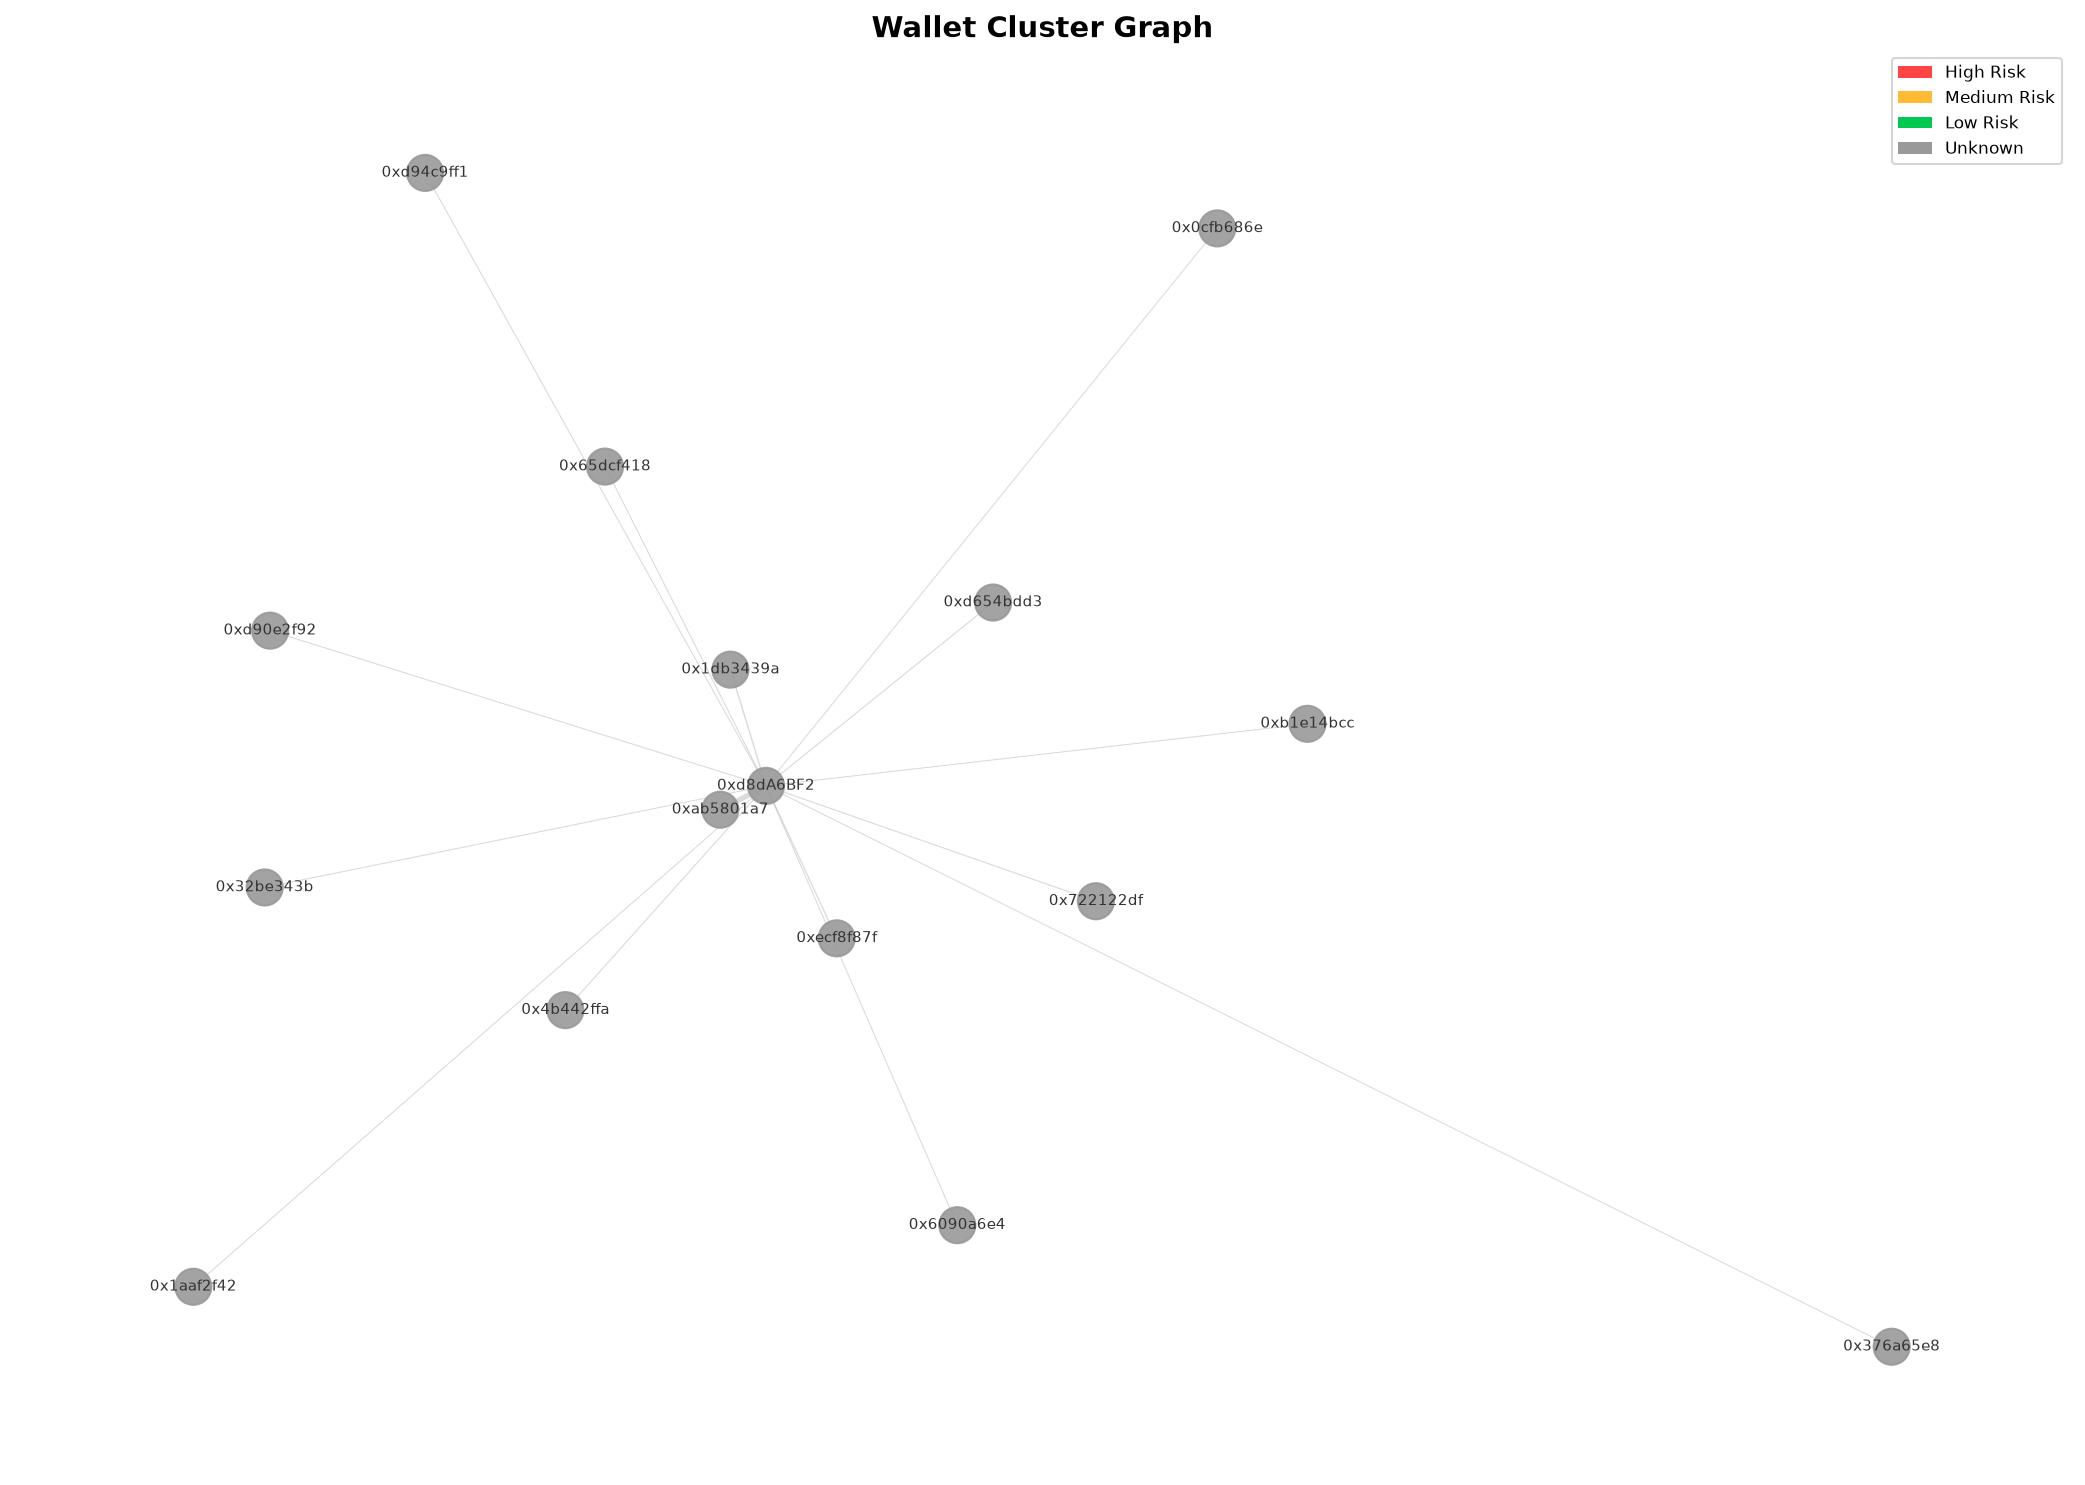

In [4]:
# Рисуем и сохраняем граф
path = graph.render("cluster_graph.png")
print(f"Граф сохранён: {path}")

# Показываем в ноутбуке
from IPython.display import Image
Image(path)

In [5]:
from onchain_detective.core.insider import InsiderDetector

# Адрес любого токена. Например, PEPE
TOKEN = "0x6982508145454Ce325dDbE47a25d4ec3d2311933"

detector = InsiderDetector(provider)

result = detector.analyze_token(TOKEN, check_top_buyers=5)

print(f"\nСоздатель: {result['creator'][:10] if result['creator'] else '?'}...")
print(f"Ранних покупателей: {result['total_early_buyers']}")
print(f"Подозрительных: {result['suspicious_count']}")
print(f"Уровень риска: {result['risk_level']}")

[Insider] Анализирую токен 0x69825081...
[Insider] Сканирую первые 100 блоков после создания
[Insider] Создатель: 0xfbfeaf0d...
[Insider] Всего трансферов: 1000
[Insider] Стартовый блок: 17047786, конечный: 17047886
[Insider] Ранних получателей: 1
[Insider] Проверяю историю 0x69825081... за 30 дней
[Insider] Токенов: 15, пампилось: 1, hit_rate: 6.7%, вердикт: green

[Insider] Итого: 1 ранних покупателей, 0 подозрительных

Создатель: 0xfbfeaf0d...
Ранних покупателей: 1
Подозрительных: 0
Уровень риска: green


In [6]:
from onchain_detective.ai.openai_analyzer import AIAnalyzer

# Данные из кластеризации
cluster_report = clusterer.export_report()
cluster_report["target_address"] = TARGET

# Данные из детектора инсайдеров (если запускал)
insider_report = result if 'result' in dir() else None

# Запускаем AI
ai = AIAnalyzer()
verdict = ai.investigate(cluster_report, insider_report)

print(f"\nУровень риска: {verdict.get('risk_level')}")
print(f"Резюме: {verdict.get('summary')}")
print(f"Вердикт: {verdict.get('verdict')}")
print(f"Рекомендация: {verdict.get('recommendation')}")
if verdict.get('red_flags'):
    print("Красные флаги:")
    for flag in verdict['red_flags']:
        print(f"  - {flag}")

[Clusterer] Найдено 1 подозрительных кластеров (из 1 всего)
[AI] Отправляю запрос...
[AI] Ошибка: Unterminated string starting at: line 3 column 14 (char 41)

Уровень риска: UNKNOWN
Резюме: Ошибка AI-анализа: Unterminated string starting at: line 3 column 14 (char 41)
Вердикт: Не удалось провести анализ
Рекомендация: WAIT


In [7]:
import sys
sys.path.insert(0, r"C:\Users\23ale\onchain_detective")

from dotenv import load_dotenv
from pathlib import Path
import os

root = Path.cwd().parent
load_dotenv(root / ".env")

from onchain_detective.ai.openai_analyzer import AIAnalyzer

# Данные из кластеризации
cluster_report = clusterer.export_report()

# Данные из детектора инсайдеров
try:
    insider_report = result
except:
    insider_report = None

ai = AIAnalyzer(
    api_key=os.getenv("OPENAI_API_KEY"),
    base_url="https://routerai.ru/api/v1",
    model="deepseek/deepseek-v4-pro",
)

print(f"Cluster report keys: {cluster_report.keys()}")
print(f"Insider report: {insider_report}")

verdict = ai.investigate(cluster_report, insider_report)

print(f"\nRaw verdict: {verdict}")
print(f"\n🔴 Уровень риска: {verdict.get('risk_level')}")
print(f"📝 Резюме: {verdict.get('summary')}")


[Clusterer] Найдено 1 подозрительных кластеров (из 1 всего)
Cluster report keys: dict_keys(['target_address', 'total_wallets_analyzed', 'total_connections', 'suspicious_clusters', 'cluster_details', 'graph_stats'])
Insider report: {'token_address': '0x6982508145454Ce325dDbE47a25d4ec3d2311933', 'creator': '0xfbfeaf0da0f2fde5c66df570133ae35f3eb58c9a', 'total_early_buyers': 1, 'suspicious_count': 0, 'top_buyers': [{'address': '0x6982508145454ce325ddbe47a25d4ec3d2311933', 'amount': 27987939.902750973, 'first_block': 17047786, 'tx_count': 1, 'distance_from_start': 0, 'history': {'address': '0x6982508145454ce325ddbe47a25d4ec3d2311933', 'tokens_bought': 15, 'pump_count': 1, 'hit_rate': 6.7, 'verdict': 'green'}}], 'suspicious': [], 'risk_level': 'green'}
[AI] Отправляю запрос...
[AI] Ответ получен. Риск: RED

Raw verdict: {'risk_level': 'RED', 'summary': 'Токен демонстрирует высокую степень централизации: все 16 проанализированных кошельков связаны в один подозрительный кластер, а сам контракт

In [8]:
import sys
sys.path.insert(0, r"C:\Users\23ale\onchain_detective")

from onchain_detective.core.whale import WhaleMonitor
from onchain_detective.utils.telegram import TelegramAlerter

# Создаём монитор
monitor = WhaleMonitor(provider)

# Загружаем список китов
whales = monitor.load_top_whales(5)
print(f"Китов на отслеживании: {len(whales)}")
for w in whales:
    print(f"  - {w[:10]}...")

# Проверяем одного кита (без отправки в Telegram)
movement = monitor.check_wallet(whales[0])
if movement:
    print(f"\nНайдено движение:")
    print(f"  Адрес: {movement['address'][:10]}...")
    print(f"  Действие: {movement['action']}")
    print(f"  Сумма: ${movement['amount_usd']:,.0f}")
    print(f"  TX: {movement['tx_hash'][:15]}...")
else:
    print("\nКрупных движений не найдено")

Китов на отслеживании: 4
  - 0xd8dA6BF2...
  - 0xBE0eB53F...
  - 0x8315177a...
  - 0x47ac0Fb4...

Крупных движений не найдено
